# Сборный проект: 'Интернет-магазин «Стримчик»

In [1]:
import pandas  as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats as st

### Откроем файл с данными и изучим общую информацию

In [2]:
data = pd.read_csv('games.csv')
data.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


#### вывод по первому пункту
- в столбцах есть пропуски
- названия столбцов начинаются с верхнего регистра 
- в нескольких столбцах неправильный тип данных 

### Подготовим данные

На этом этапе мы должны провести ряд операций:

- Заменим названия столбцов (приведем к нижнему регистру);

- Преобразуем данные в нужные типы. Опишим, в каких столбцах заменили тип данных;

- Обработаем пропуски при необходимости:

- Обратим внимание на аббревиатуру 'tbd' в столбце с оценкой пользователей. Отдельно разберем это значение и опишим, как его обработать;

- Посчитаем суммарные продажи во всех регионах и запишим их в отдельный столбец.

Заменим названия столбцов (приведем к нижнему регистру)

In [4]:
data.columns = map(str.lower, data.columns)
data.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


Найдем дубликаты и избавимся от них 

In [5]:
data[data.duplicated()].count() 

name               0
platform           0
year_of_release    0
genre              0
na_sales           0
eu_sales           0
jp_sales           0
other_sales        0
critic_score       0
user_score         0
rating             0
dtype: int64

In [6]:
data[data.duplicated(['name', 'platform', 'year_of_release', 'genre'])].count()

name               1
platform           2
year_of_release    2
genre              1
na_sales           2
eu_sales           2
jp_sales           2
other_sales        2
critic_score       1
user_score         1
rating             1
dtype: int64

In [7]:
data = data.drop_duplicates(['name', 'platform', 'year_of_release', 'genre'])
data[data.duplicated(['name', 'platform', 'year_of_release', 'genre'])].count()

name               0
platform           0
year_of_release    0
genre              0
na_sales           0
eu_sales           0
jp_sales           0
other_sales        0
critic_score       0
user_score         0
rating             0
dtype: int64

Удалили дубликаты

Обработаем пропуски при необходимости

In [8]:
data.isna().sum()

name                  1
platform              0
year_of_release     269
genre                 1
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8577
user_score         6700
rating             6765
dtype: int64

In [9]:
data = data.dropna(subset = ['name'])
data.isna().sum() 

name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         6699
rating             6764
dtype: int64

так как название нельзя восстановить, то просто удалим этот пропуск

In [10]:
data = data.dropna(subset = ['year_of_release'])
data.isna().sum() 

name                  0
platform              0
year_of_release       0
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8461
user_score         6605
rating             6676
dtype: int64

год выпуска сложно восстановить, при этом пропусков немного, это не скажется в дальнейших исследованиях. поэтому просто удалим строки с пропусками 

In [11]:
data['critic_score']

0        76.0
1         NaN
2        82.0
3        80.0
4         NaN
         ... 
16710     NaN
16711     NaN
16712     NaN
16713     NaN
16714     NaN
Name: critic_score, Length: 16443, dtype: float64

In [12]:
data['critic_score'] = data['critic_score'].fillna('-1')
data['critic_score']

0        76.0
1          -1
2        82.0
3        80.0
4          -1
         ... 
16710      -1
16711      -1
16712      -1
16713      -1
16714      -1
Name: critic_score, Length: 16443, dtype: object

пропуски заменим на -1, будем иметь в виду это при дальнейших расчетах, так как оценки бывают только от 0 до 10

In [13]:
data['user_score'] 

0          8
1        NaN
2        8.3
3          8
4        NaN
        ... 
16710    NaN
16711    NaN
16712    NaN
16713    NaN
16714    NaN
Name: user_score, Length: 16443, dtype: object

In [14]:
data['user_score'] = data['user_score'].fillna(-1)
data['user_score']

0          8
1         -1
2        8.3
3          8
4         -1
        ... 
16710     -1
16711     -1
16712     -1
16713     -1
16714     -1
Name: user_score, Length: 16443, dtype: object

tbd - это значит, что оценок пользователей не хватает, для конечной оценки. так как tbd не дает оценки, то тоже заменим на -1


In [15]:
data.loc[data['user_score'] == 'tbd', 'user_score'] = -1
data['user_score'].value_counts()

user_score
-1     8981
7.8     322
8       285
8.2     276
8.3     252
       ... 
1.3       2
1         2
0.9       2
0         1
9.7       1
Name: count, Length: 96, dtype: int64

In [16]:
data['rating'].value_counts()

rating
E       3920
T       2905
M       1536
E10+    1393
EC         8
K-A        3
AO         1
RP         1
Name: count, dtype: int64

In [17]:
data['rating'] = data['rating'].fillna('unknown')
data['rating'].value_counts()

rating
unknown    6676
E          3920
T          2905
M          1536
E10+       1393
EC            8
K-A           3
AO            1
RP            1
Name: count, dtype: int64

In [18]:
print(data.info())
print(data.isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 16443 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16443 non-null  object 
 1   platform         16443 non-null  object 
 2   year_of_release  16443 non-null  float64
 3   genre            16443 non-null  object 
 4   na_sales         16443 non-null  float64
 5   eu_sales         16443 non-null  float64
 6   jp_sales         16443 non-null  float64
 7   other_sales      16443 non-null  float64
 8   critic_score     16443 non-null  object 
 9   user_score       16443 non-null  object 
 10  rating           16443 non-null  object 
dtypes: float64(5), object(6)
memory usage: 1.5+ MB
None
name               0
platform           0
year_of_release    0
genre              0
na_sales           0
eu_sales           0
jp_sales           0
other_sales        0
critic_score       0
user_score         0
rating             0
dtype: int

все пропуски устранены 

Преобразуем данные в нужные типы. Опишим, в каких столбцах заменили тип данных

In [19]:
data['year_of_release'] = data['year_of_release'].astype('int')
data['critic_score'] = data['critic_score'].astype('int')
data['user_score'] = data['user_score'].astype('float')
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16443 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16443 non-null  object 
 1   platform         16443 non-null  object 
 2   year_of_release  16443 non-null  int64  
 3   genre            16443 non-null  object 
 4   na_sales         16443 non-null  float64
 5   eu_sales         16443 non-null  float64
 6   jp_sales         16443 non-null  float64
 7   other_sales      16443 non-null  float64
 8   critic_score     16443 non-null  int64  
 9   user_score       16443 non-null  float64
 10  rating           16443 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.5+ MB


в стобцах 'year_of_release', 'critic_score' тип данных заменили на целочисленный, а в 'user_score' поменяли на тип с плавающей запятой

In [20]:
data['total_sales'] = data.loc[:, ['na_sales','eu_sales', 'jp_sales', 'other_sales']].sum(axis=1)
data.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,-1,-1.0,unknown,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,-1,-1.0,unknown,31.38


#### вывод
- столбцы привели к нижнему регистру

- Преобразовали данные в нужные типы. в стобцах 'year_of_release', 'critic_score' тип данных заменили на целочисленный, а в 'user_score' поменяли на тип с плавающей запятой

- Обработали пропуски. избавились от дубликатов. в 'critic_score' и 'user_score' пропуски заменили на -1

- tbd - это значит, что оценок пользователей не хватает, для конечной оценки. так как tbd не дает оценки, то тоже заменим на -1

- Посчитали суммарные продажи во всех регионах и записали их в отдельный столбец.

### Проведем исследовательский анализ данных

- Посмотрим, сколько игр выпускалось в разные годы. Ответим на вопрос: "Важны ли данные за все периоды?"

- Посмотрим, как менялись продажи по платформам. Выберим платформы с наибольшими суммарными продажами и построим распределение по годам. Ответим на вопрос: "За какой характерный срок появляются новые и исчезают старые платформы?"

- Возьмем данные за соответствующий актуальный период. Актуальный период определим самостоятельно в результате исследования предыдущих вопросов. Основной фактор — эти данные помогут построить прогноз на 2017 год.

- Не будем учитывать в работе данные за предыдущие годы.

- Какие платформы лидируют по продажам, растут или падают? Выберим несколько потенциально прибыльных платформ.

- Построим график «ящик с усами» по глобальным продажам игр в разбивке по платформам. Опишим результат.

- Посмотрим, как влияют на продажи внутри одной популярной платформы отзывы пользователей и критиков. Построим диаграмму рассеяния и посчитайте корреляцию между отзывами и продажами. Сформулируем выводы.

- Соотнесем выводы с продажами игр на других платформах.

- Посмотрим на общее распределение игр по жанрам. 
- Что можно сказать о самых прибыльных жанрах? Выделяются ли жанры с высокими и низкими продажами? - разберем эти вопросы 

Посмотрим, сколько игр выпускалось в разные годы. Ответим на вопрос: "Важны ли данные за все периоды?"

In [21]:
data['year_of_release'].describe()

count    16443.000000
mean      2006.485921
std          5.875546
min       1980.000000
25%       2003.000000
50%       2007.000000
75%       2010.000000
max       2016.000000
Name: year_of_release, dtype: float64

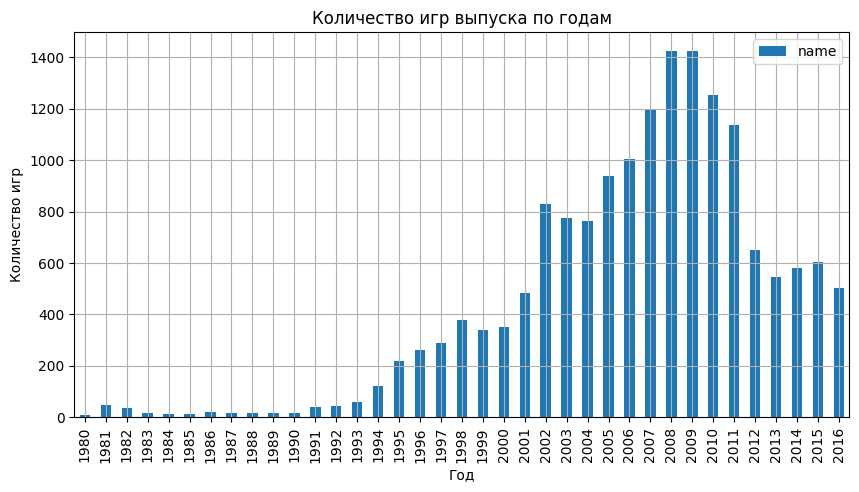

In [22]:
data.pivot_table(index='year_of_release', values='name', aggfunc='count').plot(kind='bar' , grid=True, figsize=(10, 5))
plt.title('Количество игр выпуска по годам')
plt.xlabel('Год')
plt.ylabel('Количество игр')
plt.show()

пик количества выпуска игр в год приходится на 2007 и 2008 года. игры начали приобретать популярность с 1995 года. после 2007 года выход новых игр уменьшался до 2012 года, далее выпуск новых игр стал стабильным и усредненным. 


посмотрим, как менялись продажи по платформам. Выберим платформы с наибольшими суммарными продажами и построим распределение по годам. Ответим на вопрос: "За какой характерный срок появляются новые и исчезают старые платформы?"

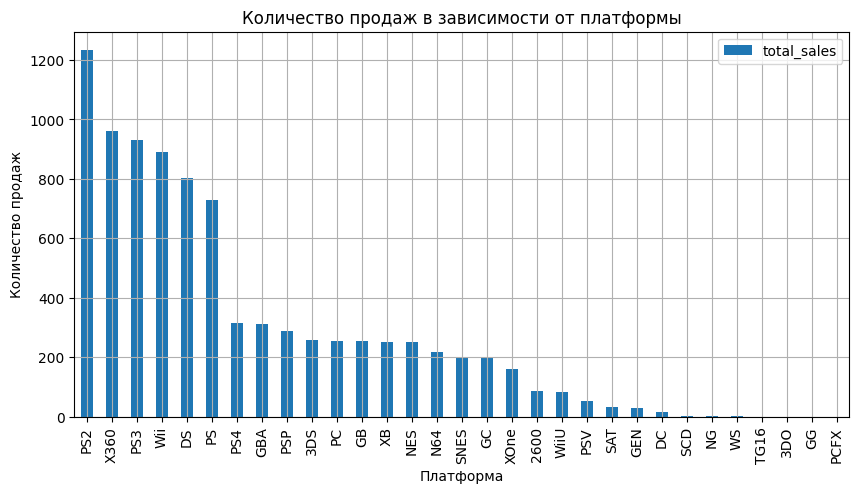

In [23]:
data.pivot_table(index='platform', values='total_sales', aggfunc='sum').sort_values(by='total_sales', ascending=False).plot(kind='bar' , grid=True, figsize=(10, 5))
plt.title('Количество продаж в зависимости от платформы')
plt.xlabel('Платформа')
plt.ylabel('Количество продаж')
plt.show()

существенно выделяется платформа - PS2, далее идут X360, PS3, Wii, DS, PS. остальные платформы имеют значительно меньше показатели

In [24]:
max_sale = data.pivot_table(index='platform', values='total_sales', aggfunc='sum').sort_values(by='total_sales', ascending=False).reset_index().head(6)['platform'].tolist()
max_sale

['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS']

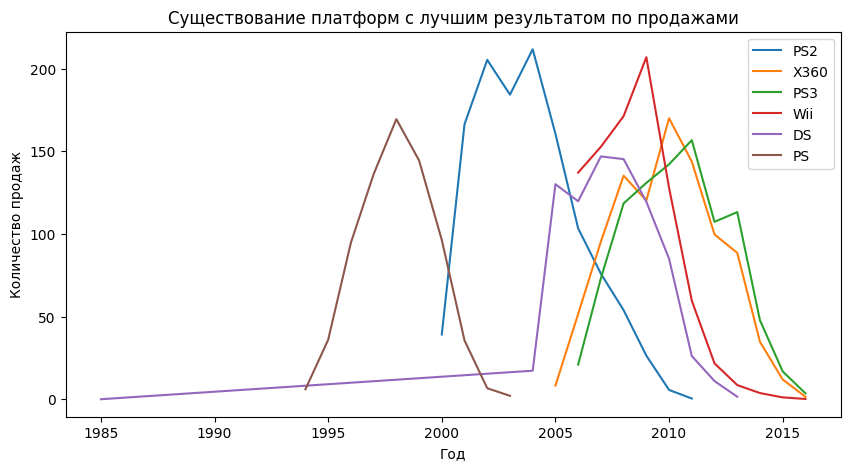

In [25]:
for b in max_sale:
    (
    data.query('platform == @b')
    .pivot_table(index = 'year_of_release', values = 'total_sales', aggfunc = 'sum')
    .sort_values('year_of_release', ascending = False)['total_sales']
    .plot(figsize = (10, 5), label=b)
    )
    plt.title('Существование платформ с лучшим результатом по продажами')
    plt.xlabel('Год')
    plt.ylabel('Количество продаж')
    plt.legend()

Можно сделать выводы, что платформы существуют в около 10 лет, платформы приобретают свой пик в среднем спустя 5 лет от начала релиза.

За какой характерный срок появляются новые и исчезают старые платформы?- новые платформы обретают свою популярность в течение первых 5 лет, следующие 5 лет идут на спад до прекращения существования.

In [26]:
data.pivot_table(index='platform', values='year_of_release').round(2)

,year_of_release
platform,
2600,1982.14
3DO,1994.67
3DS,2013.13
DC,1999.94
DS,2008.19
GB,1995.96
GBA,2003.21
GC,2003.40
GEN,1993.04


2008 год выпуска средний год выпуска платформы DS. поэтому 1985-2000 можно не учитывать, как мы и сделали, на наш итоговый вывод этот выброс не повлиял 

Какие платформы лидируют по продажам, растут или падают? Выберим несколько потенциально прибыльных платформ.

In [27]:
actual_period = data[data['year_of_release'] >= 2013]
actual_period

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
16,Grand Theft Auto V,PS3,2013,Action,7.02,9.09,0.98,3.96,97,8.2,M,21.05
23,Grand Theft Auto V,X360,2013,Action,9.66,5.14,0.06,1.41,97,8.1,M,16.27
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,-1,-1.0,unknown,14.63
33,Pokemon X/Pokemon Y,3DS,2013,Role-Playing,5.28,4.19,4.35,0.78,-1,-1.0,unknown,14.60
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97,8.3,M,12.62
...,...,...,...,...,...,...,...,...,...,...,...,...
16703,Strawberry Nauts,PSV,2016,Adventure,0.00,0.00,0.01,0.00,-1,-1.0,unknown,0.01
16707,Aiyoku no Eustia,PSV,2014,Misc,0.00,0.00,0.01,0.00,-1,-1.0,unknown,0.01
16710,Samurai Warriors: Sanada Maru,PS3,2016,Action,0.00,0.00,0.01,0.00,-1,-1.0,unknown,0.01
16712,Haitaka no Psychedelica,PSV,2016,Adventure,0.00,0.00,0.01,0.00,-1,-1.0,unknown,0.01


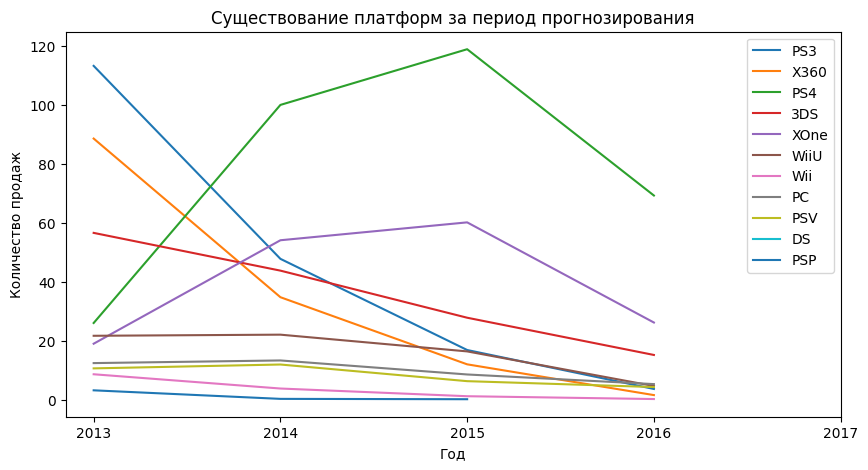

In [28]:
for b in actual_period['platform'].unique():
    (actual_period.query('platform == @b')
    .pivot_table(index = 'year_of_release', values = 'total_sales', aggfunc = 'sum')
    .sort_values('year_of_release', ascending = False)['total_sales']
    .plot(kind='line', figsize = (10, 5), label=b))
    
    plt.title('Существование платформ за период прогнозирования')
    plt.xticks(np.arange(2013, 2018, step=1))
    plt.xlabel('Год')
    plt.ylabel('Количество продаж')
    plt.legend()

по графику видно, что у всех консолей идет спад, но консоли: PS4 и XOne только недавно начали свое движение вниз по продажам. поэтому весь упор будет идти на эти две консоли. 3DS замыкает тройку лидеров

Построим график «ящик с усами» по глобальным продажам игр в разбивке по платформам. Опишим результат

In [29]:
actual_period.describe()

,year_of_release,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,total_sales
count,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000
mean,2014.477385,0.196019,0.175652,0.063045,0.053726,31.407524,3.048724,0.488442
std,1.089439,0.547730,0.512451,0.233997,0.165693,37.282494,3.963069,1.235226
min,2013.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,-1.000000,0.010000
25%,2014.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,-1.000000,0.030000
50%,2014.000000,0.020000,0.030000,0.010000,0.010000,-1.000000,3.500000,0.110000
75%,2015.000000,0.150000,0.130000,0.050000,0.040000,72.000000,7.100000,0.400000
max,2016.000000,9.660000,9.090000,4.350000,3.960000,97.000000,9.300000,21.050000


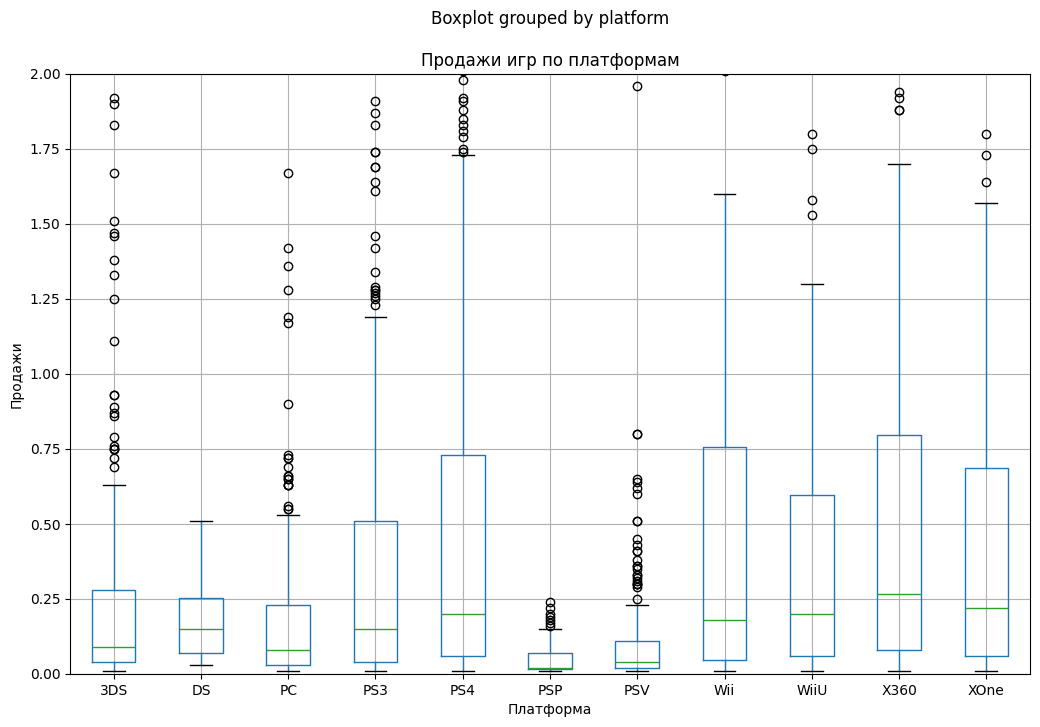

In [30]:
actual_period.boxplot(by='platform', column=['total_sales'], figsize=(12,8))
plt.ylim(0,2)
plt.title('Продажи игр по платформам')
plt.xlabel('Платформа')
plt.ylabel('Продажи')
plt.show()

- у каждой платформы есть выбросы

- платформы PS4 и XOne имеют близкие значение


Посмотрим, как влияют на продажи внутри одной популярной платформы отзывы пользователей и критиков. Построим диаграмму рассеяния и посчитайте корреляцию между отзывами и продажами. Сформулируем выводы.


In [31]:
actual_period_5 = (actual_period.pivot_table(index='platform', values='total_sales', aggfunc='sum')
    .sort_values(by='total_sales', ascending=False)
    .reset_index().head(5)['platform'].tolist())                         
actual_period_5

['PS4', 'PS3', 'XOne', '3DS', 'X360']

Корреляция между оценками пользователей и продажами по платформе PS4  = -0.03195711020455643


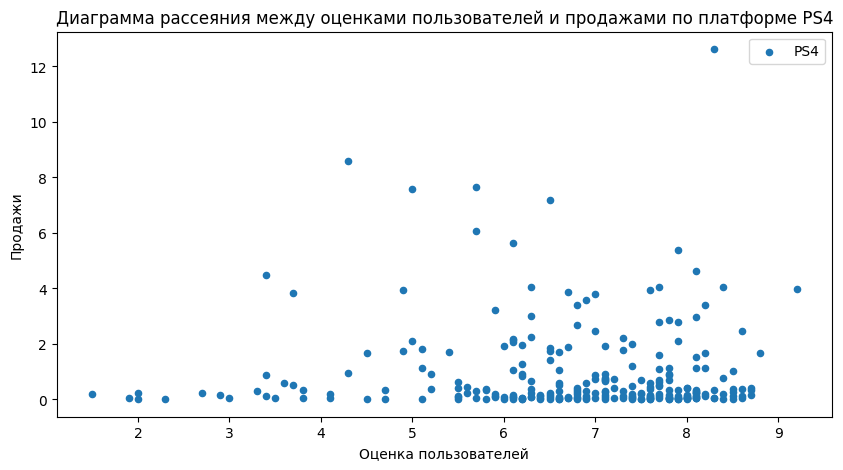

Корреляция между оценками пользователей и продажами по платформе PS3  = 0.0023944027357566907


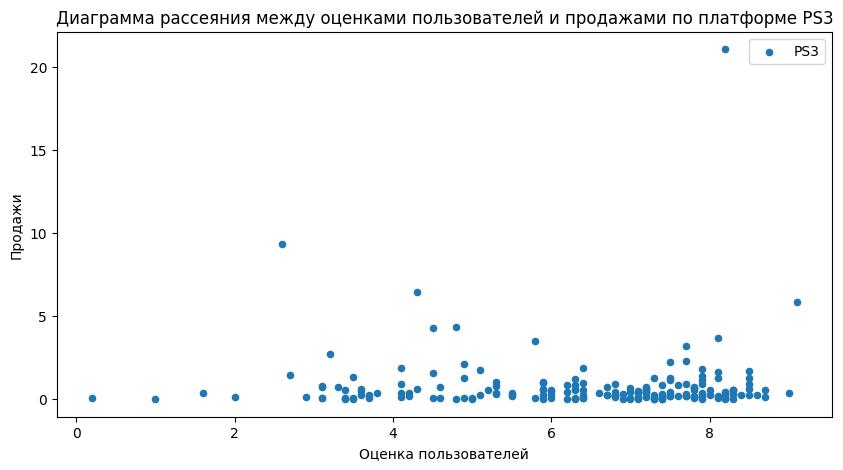

Корреляция между оценками пользователей и продажами по платформе XOne  = -0.06892505328279416


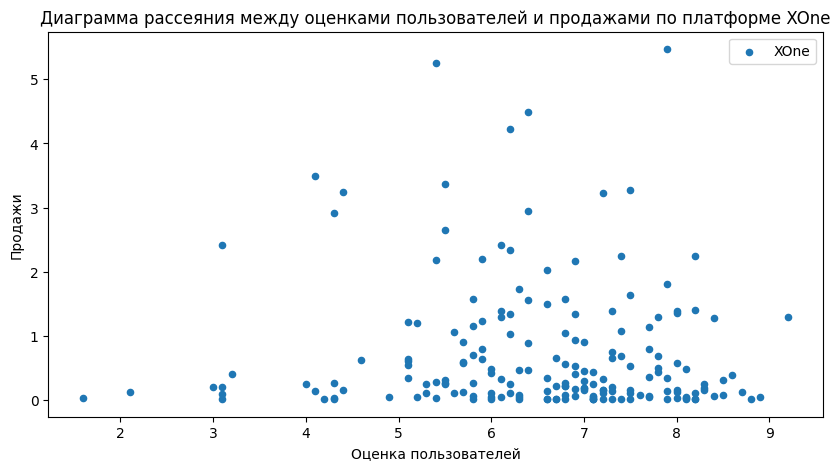

Корреляция между оценками пользователей и продажами по платформе 3DS  = 0.24150411773563016


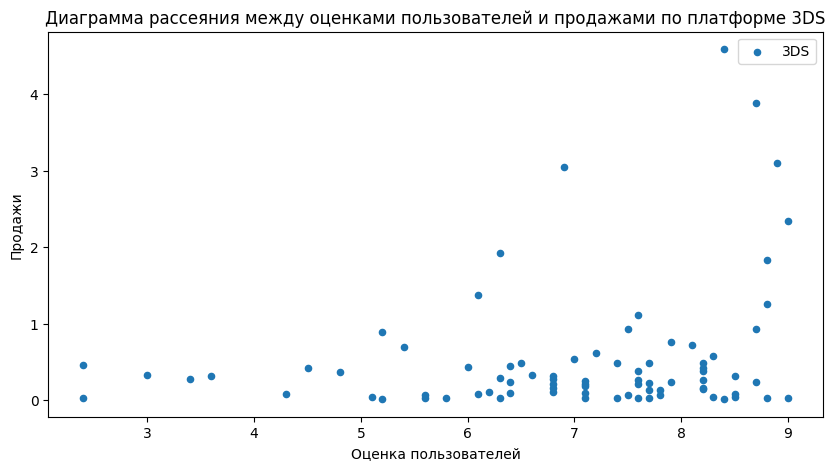

Корреляция между оценками пользователей и продажами по платформе X360  = -0.011742185147181351


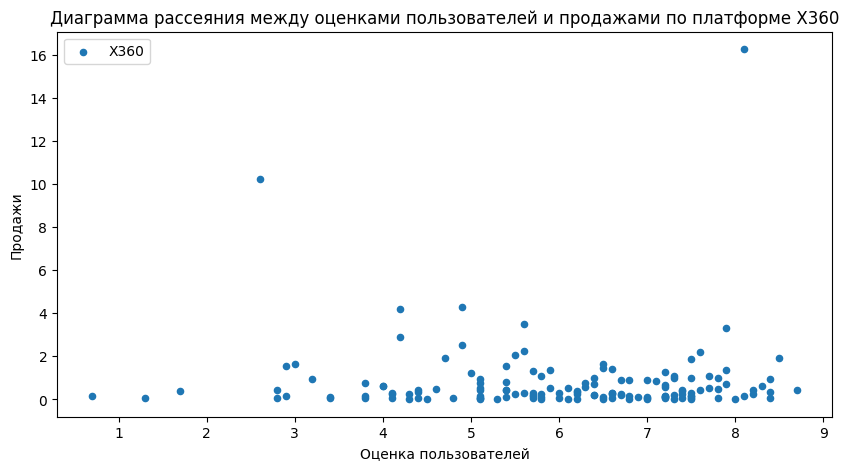

In [32]:
for b in actual_period_5:
    (
    actual_period.query('platform == @b and user_score > -1')
        .plot(x='user_score', 
          y='total_sales', 
          kind='scatter', 
          figsize=(10, 5))
    )
    plt.title(f'Диаграмма рассеяния между оценками пользователей и продажами по платформе {b}')
    plt.xlabel('Оценка пользователей')
    plt.ylabel('Продажи')
    plt.legend([b])
    print(f'Корреляция между оценками пользователей и продажами по платформе {b}  =', actual_period.query('platform == @b and user_score > -1')['user_score'].corr(actual_period.query('platform == @b and user_score > -1')['total_sales']))
    plt.show()

отобрали 5 лучших платформ. 

по посторенным диаграммам можно сказать, что сильной зависимост нет между оценками пользователей и продажами

Корреляция между оценками критиков и продажами по платформе PS4  = 0.4065679020617816


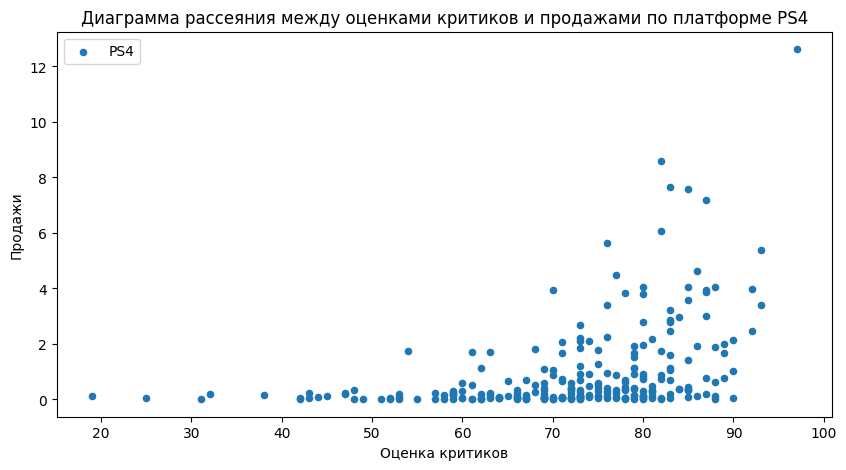

Корреляция между оценками критиков и продажами по платформе PS3  = 0.3342853393371919


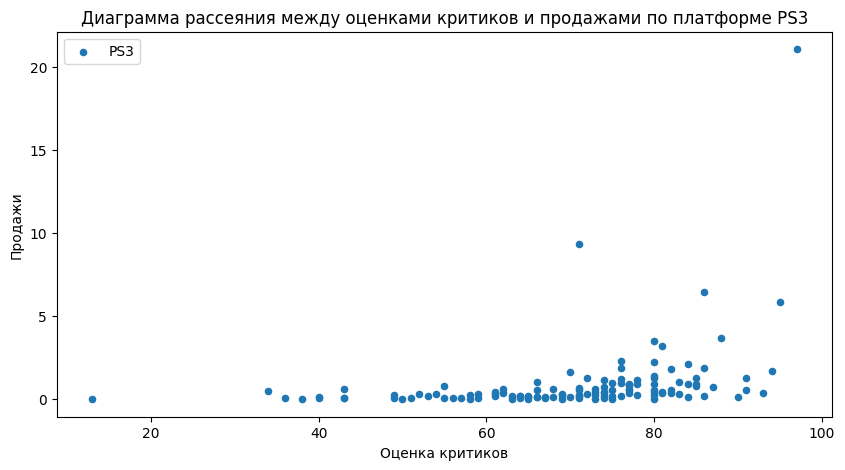

Корреляция между оценками критиков и продажами по платформе XOne  = 0.4169983280084017


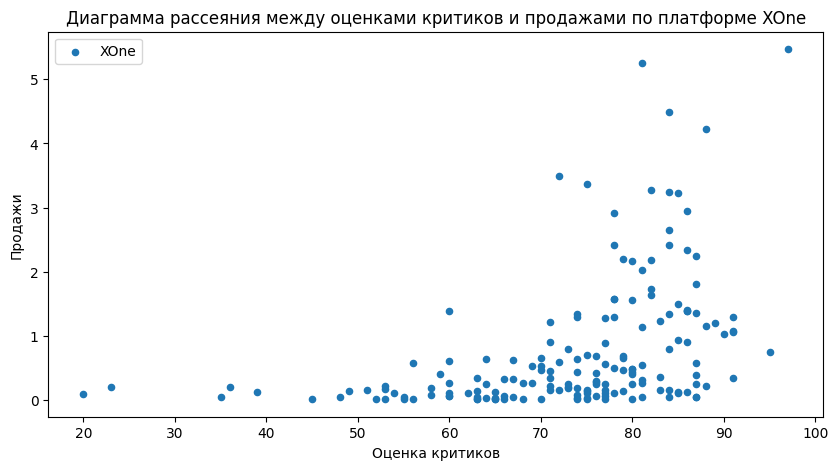

Корреляция между оценками критиков и продажами по платформе 3DS  = 0.3570566142288103


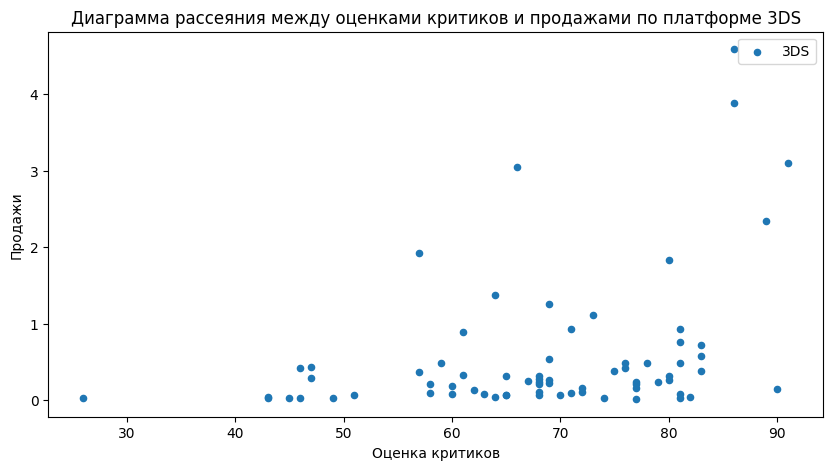

Корреляция между оценками критиков и продажами по платформе X360  = 0.3503445460228664


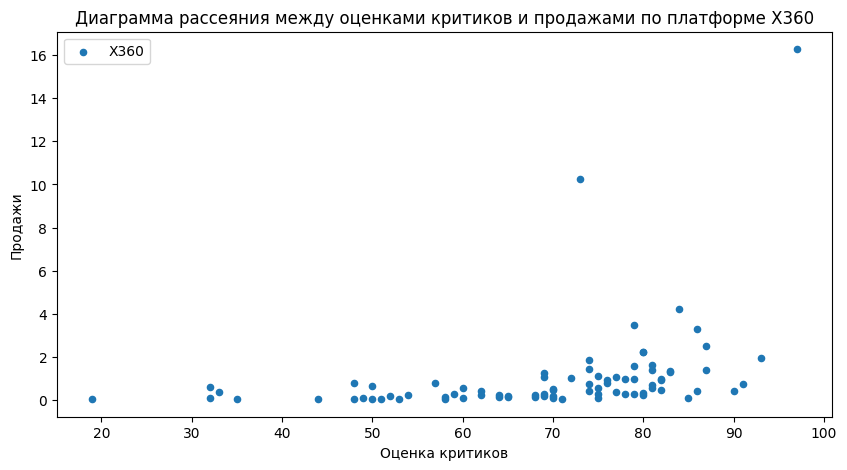

In [33]:
for b in actual_period_5:
    (
    actual_period.query('platform == @b and critic_score > -1')
        .plot(x='critic_score', 
          y='total_sales', 
          kind='scatter', 
          figsize=(10, 5))
    )
    plt.title(f'Диаграмма рассеяния между оценками критиков и продажами по платформе {b}')
    plt.xlabel('Оценка критиков')
    plt.ylabel('Продажи')
    plt.legend([b])
    print(f'Корреляция между оценками критиков и продажами по платформе {b}  =', actual_period.query('platform == @b and critic_score > -1')['critic_score'].corr(actual_period.query('platform == @b and critic_score > -1')['total_sales']))
    plt.show()

по посторенным диаграммам можно сказать, что опять же сильной зависимости нет, но оценки критиков учитывают в большей степени, чем оценки пользователей

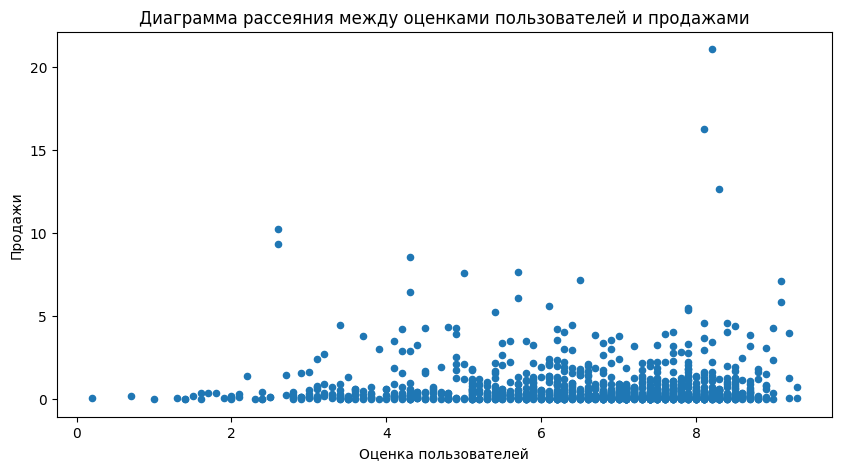

In [34]:
actual_period.query('user_score > -1').plot(x='user_score', y='total_sales', kind='scatter', figsize=(10, 5))
plt.title('Диаграмма рассеяния между оценками пользователей и продажами')
plt.xlabel('Оценка пользователей')
plt.ylabel('Продажи')
plt.show()

In [35]:
actual_period.query('user_score > -1')['user_score'].corr(actual_period['total_sales'])

np.float64(-0.0026078133545982688)

информация для анализа оценок пользователей и продажами

теперь сделаем такой же срез данных по оценкам критиков и продажами 

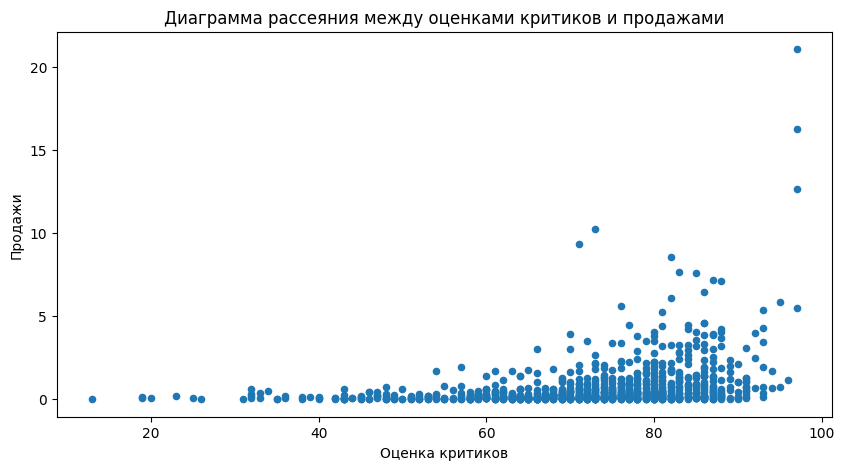

In [36]:
actual_period.query('critic_score > -1').plot(x='critic_score', y='total_sales', kind='scatter', figsize=(10, 5))
plt.title('Диаграмма рассеяния между оценками критиков и продажами')
plt.xlabel('Оценка критиков')
plt.ylabel('Продажи')
plt.show()

In [37]:
actual_period.query('critic_score > -1')['critic_score'].corr(actual_period['total_sales'])

np.float64(0.3136995151027369)

рассматривая первые 5 платформ по диаграммам, можно сделать окончательный вывод, что мнение критиков влияет больше.

Соотнесем выводы с продажами игр на других платформах.

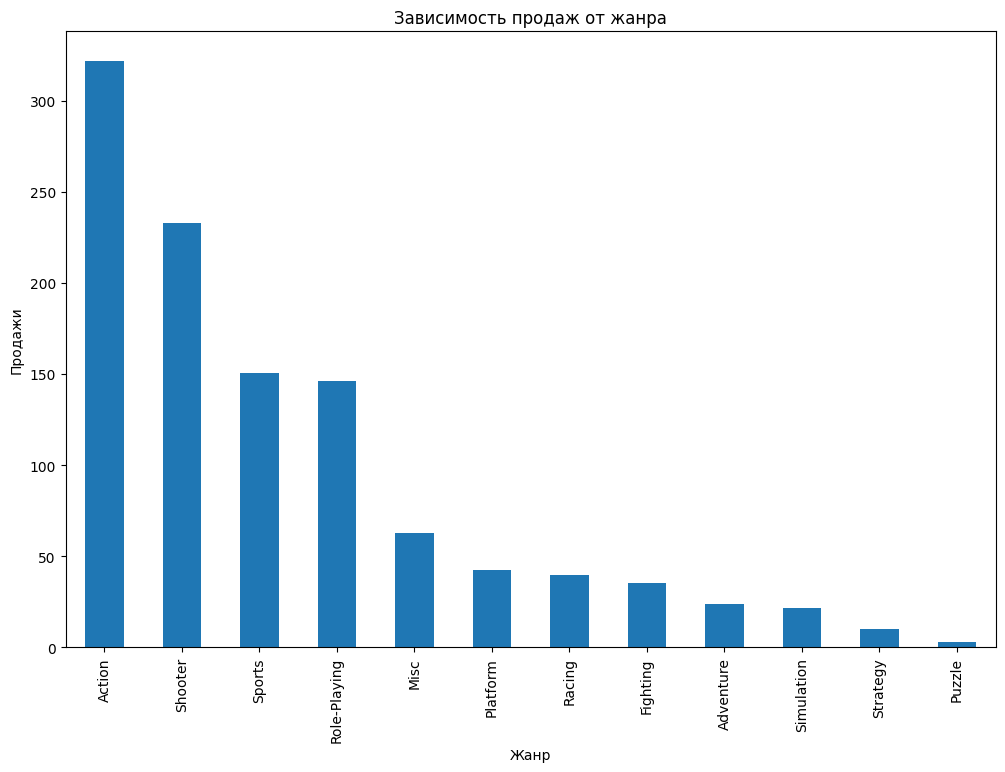

In [38]:
(actual_period
 .pivot_table(index='genre', values='total_sales', aggfunc='sum')
 .sort_values('total_sales', ascending=False)
 .plot(kind='bar', y='total_sales', figsize=(12, 8), legend=False)
)
plt.title('Зависимость продаж от жанра')
plt.xlabel('Жанр')
plt.ylabel('Продажи')
plt.show()

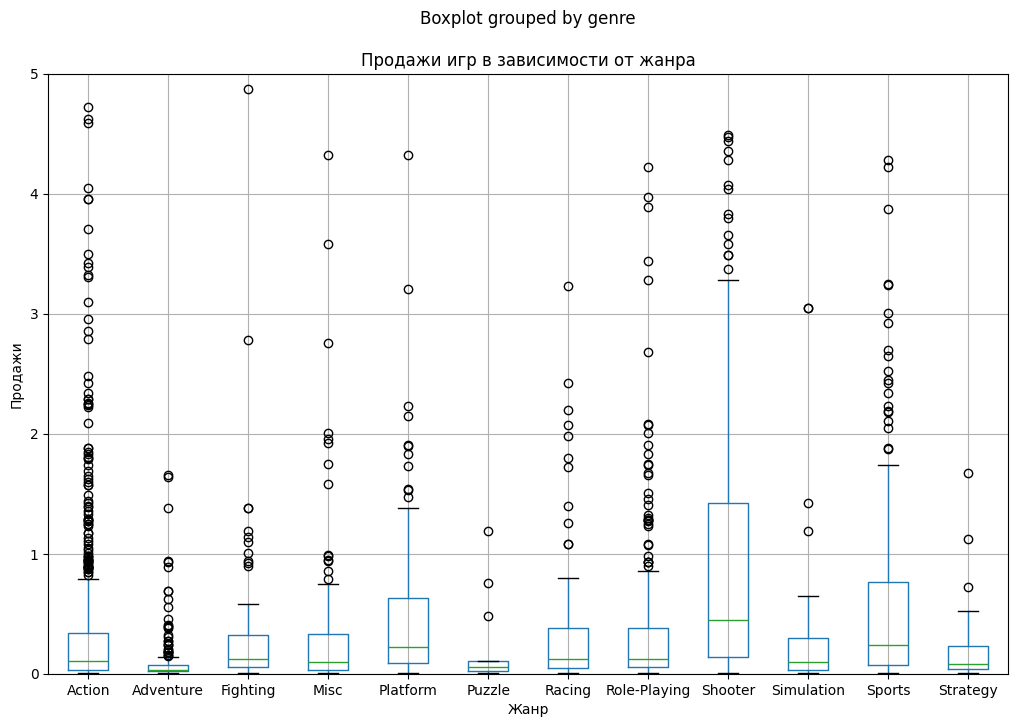

In [39]:
actual_period.boxplot(by='genre', column=['total_sales'], figsize=(12,8))
plt.ylim(0,5)
plt.title('Продажи игр в зависимости от жанра')
plt.xlabel('Жанр')
plt.ylabel('Продажи')
plt.show()

In [40]:
actual_period.pivot_table(index='genre', values='total_sales', aggfunc='median').sort_values('total_sales', ascending=False)

,total_sales
genre,
Shooter,0.450
Sports,0.240
Platform,0.225
Role-Playing,0.125
Fighting,0.125
Racing,0.120
Action,0.110
Simulation,0.100
Misc,0.100


1)За последние года наиболее востребованными являются Action, Shooter.

2)Для прогнозирование на ближайшие года следует выделить жанры Shooter и Sports, так как они имеют большие медианные значения прибыли 

#### вывод

- пик количества выпуска игр в год приходится на 2007 и 2008 года. игры начали приобретать популярность с 1995 года. после 2007 года выход новых игр уменьшался до 2012 года, далее выпуск новых игр стал стабильным и усредненным.

- можно сделать выводы, что платформы существуют в около 10 лет, платформы приобретают свой пик в среднем спустя 5 лет от начала релиза.

- у всех консолей идет спад, но консоли: PS4 и XOne только недавно начали свое движение вниз по продажам. поэтому весь упор будет идти на эти две консоли.

- сильной зависимост нет между оценками пользователей и продажами. мнение критиков влияет больше.

- За последние года наиболее востребованными являются Action, Shooter. Для прогнозирование на ближайшие года следует выделить жанры Shooter и Sports, так как они имеют большие медианные значения прибыли

### Составим портрет пользователя каждого региона

Определим для пользователя каждого региона (NA, EU, JP):

- Самые популярные платформы (топ-5). Опишим различия в долях продаж.

- Самые популярные жанры (топ-5). Поясним разницу.

- Влияет ли рейтинг ESRB на продажи в отдельном регионе?

Самые популярные платформы (топ-5)

In [41]:
america = actual_period[actual_period.year_of_release >= 2013].groupby('platform')['na_sales'].agg(na_sales='sum').nlargest(5, 'na_sales').reset_index()
europe = actual_period[actual_period.year_of_release >= 2013].groupby('platform')['eu_sales'].agg(eu_sales='sum').nlargest(5, 'eu_sales').reset_index()
japan = actual_period[actual_period.year_of_release >= 2013].groupby('platform')['jp_sales'].agg(jp_sales='sum').nlargest(5, 'jp_sales').reset_index()

In [42]:
print(america)
print(europe)
print(japan)

  platform  na_sales
0      PS4    108.74
1     XOne     93.12
2     X360     81.66
3      PS3     63.50
4      3DS     38.20
  platform  eu_sales
0      PS4    141.09
1      PS3     67.81
2     XOne     51.59
3     X360     42.52
4      3DS     30.96
  platform  jp_sales
0      3DS     67.81
1      PS3     23.35
2      PSV     18.59
3      PS4     15.96
4     WiiU     10.88


создали три таблицы по каждому региону из 5 лучших платформ

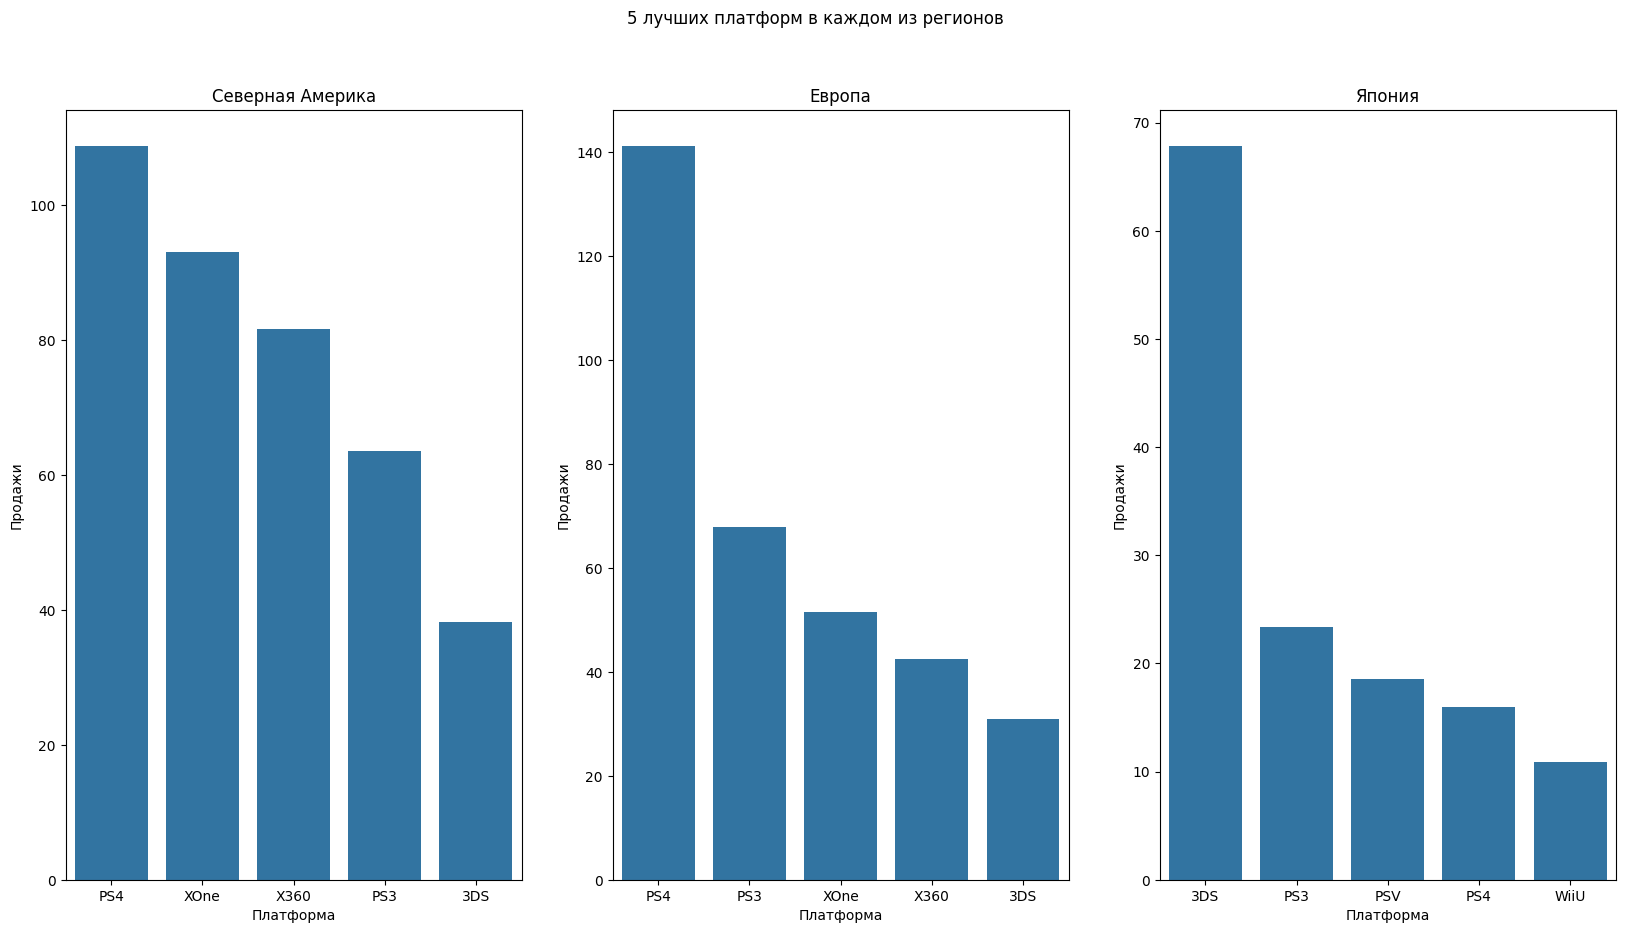

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(20, 10))
fig.suptitle('5 лучших платформ в каждом из регионов')

sns.barplot(y='na_sales', x='platform', data=america, ax=ax[0])
ax[0].set_title('Северная Америка')
ax[0].set_ylabel('Продажи')
ax[0].set_xlabel('Платформа')

sns.barplot(y='eu_sales', x='platform', data=europe, ax=ax[1])
ax[1].set_title('Европа')
ax[1].set_ylabel('Продажи')
ax[1].set_xlabel('Платформа')

sns.barplot(y='jp_sales', x='platform', data=japan, ax=ax[2])
ax[2].set_title('Япония')
ax[2].set_ylabel('Продажи')
ax[2].set_xlabel('Платформа')
plt.show()

В Северной Америке 1 место занимает платформа PS4, в Европе - PS4, а в Японии 3DS

Самые популярные жанры (топ-5)

In [44]:
america_genre = actual_period[actual_period.year_of_release >= 2013].groupby('genre')['na_sales'].agg(na_sales='sum').nlargest(5, 'na_sales').reset_index()
europe_genre = actual_period[actual_period.year_of_release >= 2013].groupby('genre')['eu_sales'].agg(eu_sales='sum').nlargest(5, 'eu_sales').reset_index()
japan_genre = actual_period[actual_period.year_of_release >= 2013].groupby('genre')['jp_sales'].agg(jp_sales='sum').nlargest(5, 'jp_sales').reset_index()

In [45]:
print(america_genre)
print(europe_genre)
print(japan_genre)

          genre  na_sales
0        Action    126.05
1       Shooter    109.74
2        Sports     65.27
3  Role-Playing     46.40
4          Misc     27.49
          genre  eu_sales
0        Action    118.13
1       Shooter     87.86
2        Sports     60.52
3  Role-Playing     36.97
4        Racing     20.19
          genre  jp_sales
0  Role-Playing     51.04
1        Action     40.49
2          Misc      9.20
3      Fighting      7.65
4       Shooter      6.61


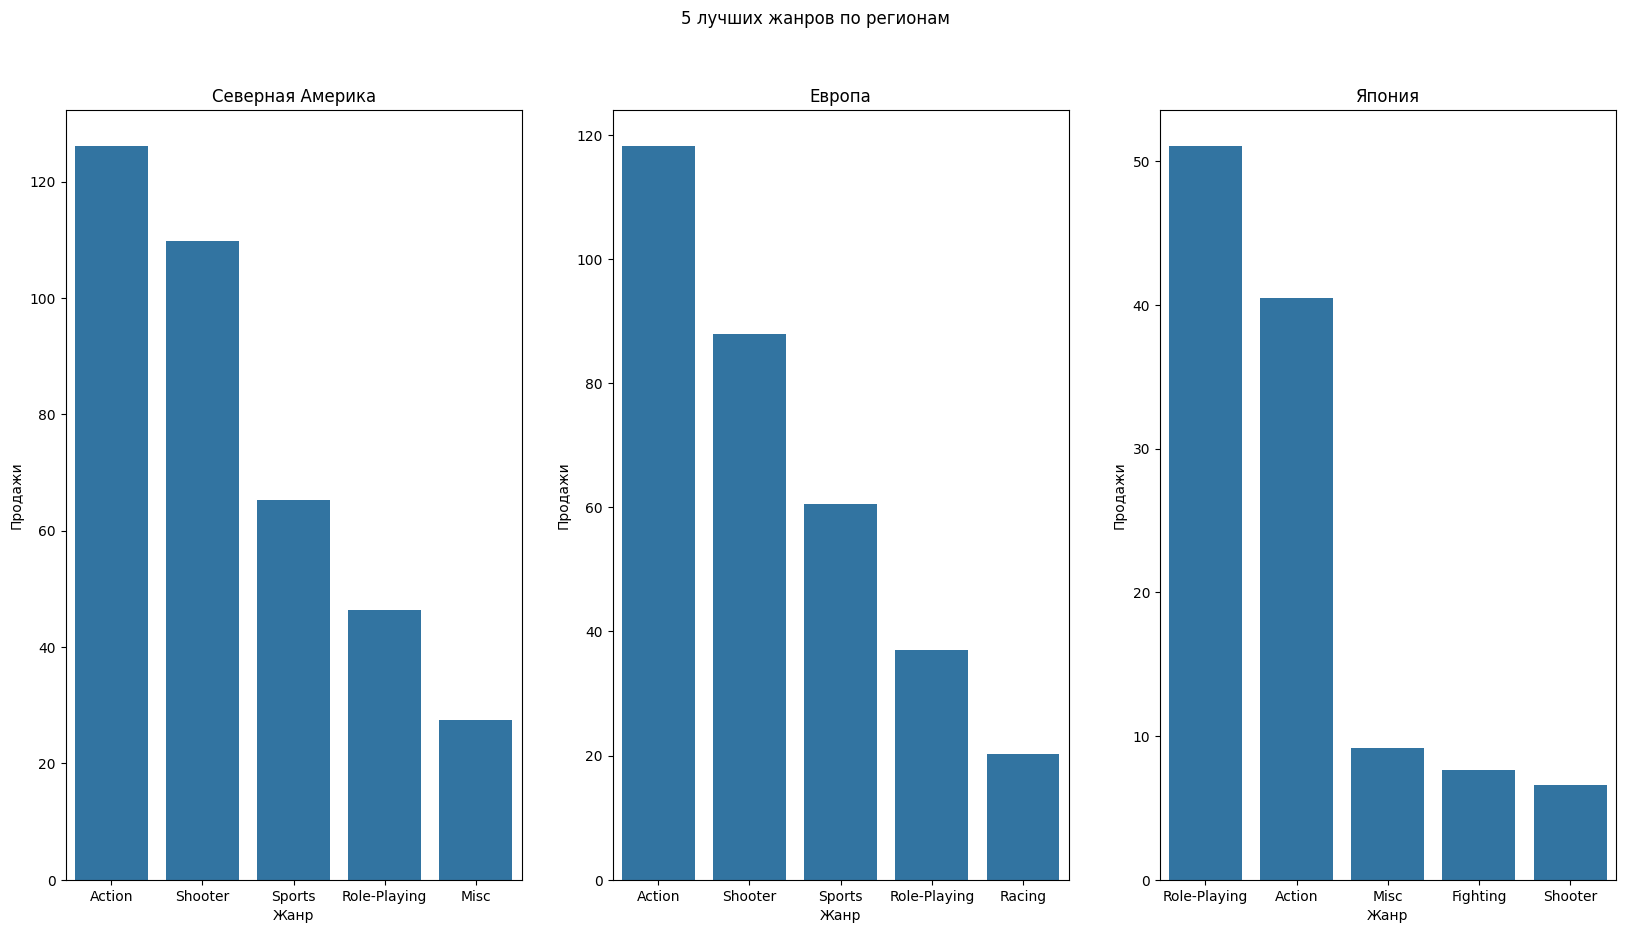

In [46]:
fig, ax = plt.subplots(1, 3, figsize=(20, 10))
fig.suptitle('5 лучших жанров по регионам')

sns.barplot(y='na_sales', x='genre', data=america_genre, ax=ax[0])
ax[0].set_title('Северная Америка')
ax[0].set_ylabel('Продажи')
ax[0].set_xlabel('Жанр')

sns.barplot(y='eu_sales', x='genre', data=europe_genre, ax=ax[1])
ax[1].set_title('Европа')
ax[1].set_ylabel('Продажи')
ax[1].set_xlabel('Жанр')

sns.barplot(y='jp_sales', x='genre', data=japan_genre, ax=ax[2])
ax[2].set_title('Япония')
ax[2].set_ylabel('Продажи')
ax[2].set_xlabel('Жанр')
plt.show()

распределение по жанрам у Северной Аммерики и Европы почти одинаковое, самый популярный жанр - action. в Японии самый популярный жанр - role-playing, action на втором месте

Влияет ли рейтинг ESRB на продажи в отдельном регионе?

In [47]:
america_rating = actual_period[actual_period.year_of_release >= 2013].groupby('rating')['na_sales'].agg(na_sales='sum').nlargest(5, 'na_sales').reset_index()
europe_rating = actual_period[actual_period.year_of_release >= 2013].groupby('rating')['eu_sales'].agg(eu_sales='sum').nlargest(5, 'eu_sales').reset_index()
japan_rating = actual_period[actual_period.year_of_release >= 2013].groupby('rating')['jp_sales'].agg(jp_sales='sum').nlargest(5, 'jp_sales').reset_index()

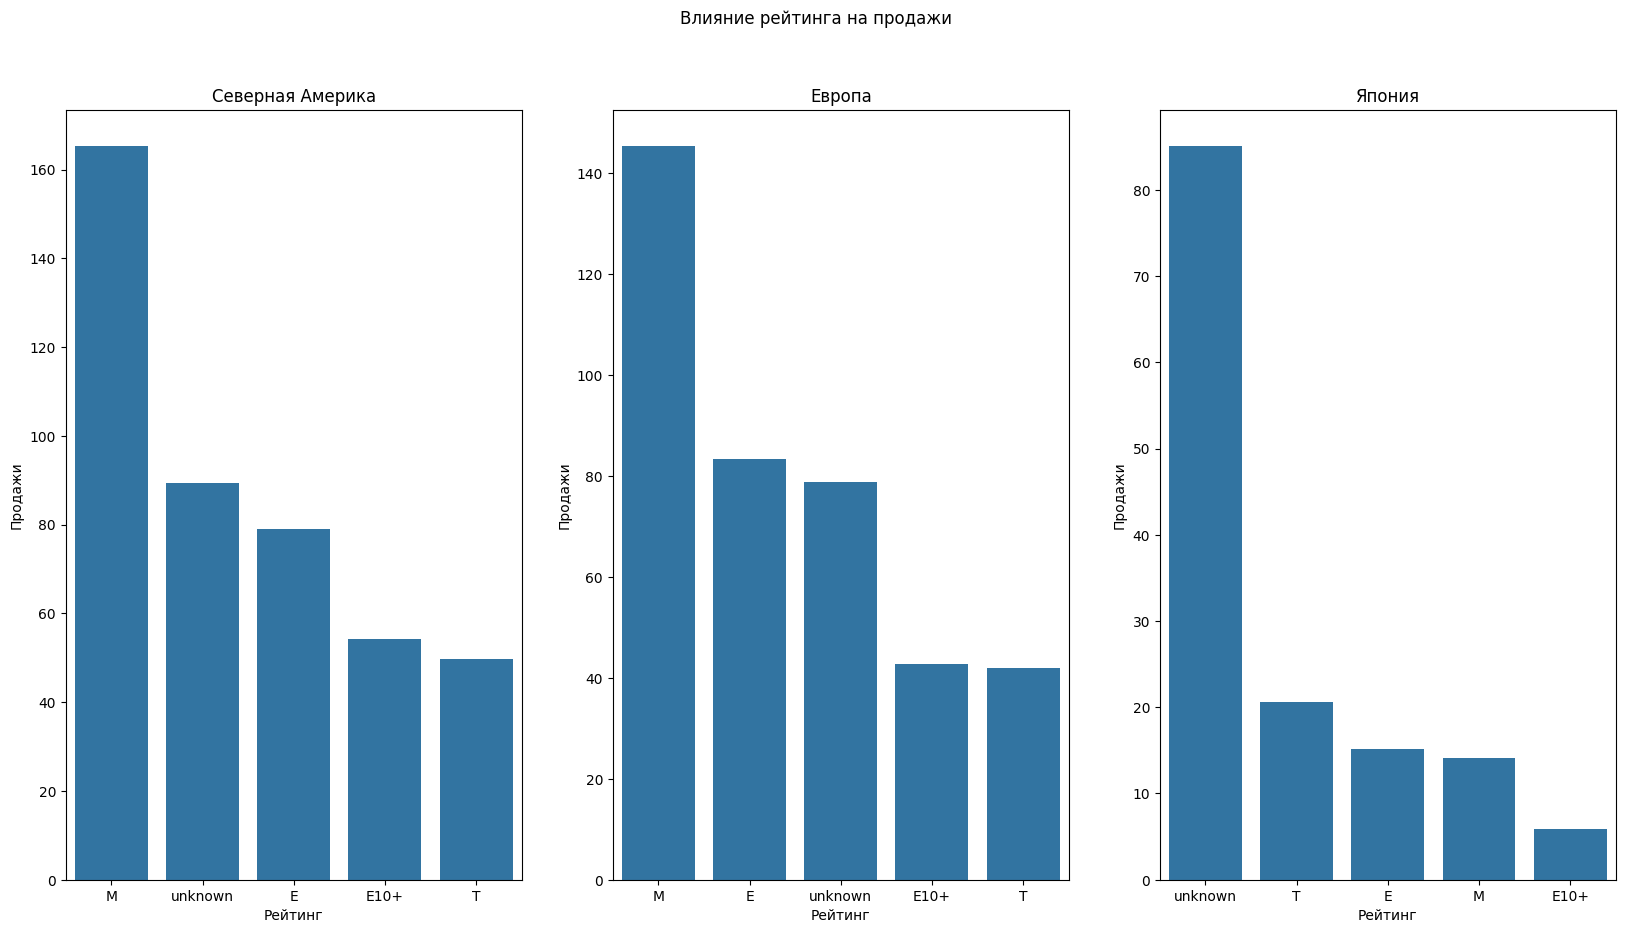

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(20, 10))
fig.suptitle('Влияние рейтинга на продажи')

sns.barplot(y='na_sales', x='rating', data=america_rating, ax=ax[0])
ax[0].set_title('Северная Америка')
ax[0].set_ylabel('Продажи')
ax[0].set_xlabel('Рейтинг')

sns.barplot(y='eu_sales', x='rating', data=europe_rating, ax=ax[1])
ax[1].set_title('Европа')
ax[1].set_ylabel('Продажи')
ax[1].set_xlabel('Рейтинг')

sns.barplot(y='jp_sales', x='rating', data=japan_rating, ax=ax[2])
ax[2].set_title('Япония')
ax[2].set_ylabel('Продажи')
ax[2].set_xlabel('Рейтинг')
plt.show()

в Северной Америки и Европе больше всего категории М, в Японии большая неопределенность, а затем Т

- В Северной Америке 1 место занимает платформа PS4, в Европе - PS4, а в Японии 3DS

- распределение по жанрам у Северной Аммерики и Европы почти одинаковое, самый популярный жанр - action. в Японии самый популярный жанр - role-playing, action на втором месте

- в Северной Америки и Европе больше всего категории М, в Японии большая неопределенность, а затем Т

### Проверьте гипотезы


- Средние пользовательские рейтинги платформ Xbox One и PC одинаковые;

- Средние пользовательские рейтинги жанров Action (англ. «действие», экшен-игры) и Sports (англ. «спортивные соревнования») разные.

Задайте самостоятельно пороговое значение alpha.

Поясните:
    
- Как вы сформулировали нулевую и альтернативную гипотезы;
- Какой критерий применили для проверки гипотез и почему.

проверим: Средние пользовательские рейтинги платформ Xbox One и PC одинаковые

In [50]:
xone = actual_period.query('platform == "XOne" and user_score > -1')
xone['user_score'].describe()

count    182.000000
mean       6.521429
std        1.380941
min        1.600000
25%        5.800000
50%        6.800000
75%        7.500000
max        9.200000
Name: user_score, dtype: float64

In [51]:
pc = actual_period.query("platform == 'PC' and user_score > -1")
pc['user_score'].describe()

count    155.000000
mean       6.269677
std        1.742381
min        1.400000
25%        5.300000
50%        6.800000
75%        7.600000
max        9.300000
Name: user_score, dtype: float64

Н0 - Средние пользовательские рейтинги платформ XOne и PC равны

Н1 - Средние пользовательские рейтинги платформ XOne и PC не равны

In [52]:
results = st.ttest_ind(xone['user_score'], pc['user_score'],equal_var=False,alternative='two-sided')
print(results.pvalue)

alpha = 0.05
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

0.14759594013430463
Не получилось отвергнуть нулевую гипотезу


Нулевая гипотеза не отвергнута, следовательно, можно предположить, что XOne и PC равны, при alpha=0.05

p-значение - это вероятность, принадлежащая промежутку от 0 до 1, если итоговый ответ входит в наш интервал, то наша гипотеза правдива  

In [53]:
# Приведены два датасета: сумма покупок, совершённых за месяц посетителями ...

sample_1 = [3071, 3636, 3454, 3151, 2185, 3259, 1727, 2263, 2015,
2582, 4815, 633, 3186, 887, 2028, 3589, 2564, 1422, 1785,
3180, 1770, 2716, 2546, 1848, 4644, 3134, 475, 2686,
1838, 3352]
sample_2 = [1211, 1228, 2157, 3699, 600, 1898, 1688, 1420, 5048, 3007,
509, 3777, 5583, 3949, 121, 1674, 4300, 1338, 3066,
3562, 1010, 2311, 462, 863, 2021, 528, 1849, 255,
1740, 2596]
alpha = .05 # критический уровень статистической значимости
# если p-value окажется меньше него - отвергнем гипотезу
results = st.ttest_ind(
sample_1,
sample_2)
print('p-значение:', results.pvalue)
if (results.pvalue < alpha):
    print("Отвергаем нулевую гипотезу")
else:
    print("Не получилось отвергнуть нулевую гипотезу")

p-значение: 0.19124505225722097
Не получилось отвергнуть нулевую гипотезу


проверим: Средние пользовательские рейтинги жанров Action (англ. «действие», экшен-игры) и Sports (англ. «спортивные соревнования») разные.


In [54]:
action = actual_period.query('genre == "Action" and user_score > -1')
print(action['user_score'].describe())
sports = actual_period.query("genre == 'Sports' and user_score > -1")
print(sports['user_score'].describe())

count    389.000000
mean       6.837532
std        1.330173
min        2.000000
25%        6.300000
50%        7.100000
75%        7.800000
max        9.100000
Name: user_score, dtype: float64
count    160.000000
mean       5.238125
std        1.783427
min        0.200000
25%        4.100000
50%        5.500000
75%        6.500000
max        8.800000
Name: user_score, dtype: float64


Н0 - Средние пользовательские рейтинги жанров Action и Sports равны

Н1 - Средние пользовательские рейтинги жанров Action и Sports не равны

In [55]:
results = st.ttest_ind(action['user_score'], sports['user_score'],equal_var=False,alternative='two-sided')

print(results.pvalue)

alpha = 0.05
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

1.4460039700704318e-20
Отвергаем нулевую гипотезу


Нулевая гипотеза отвергнута, значит,можно скать, что Action и Sports не равны, при alpha=0.05

критерии гипотез:

мы применяли t-тест, так как у нас попарное сравнение, этот тест используется чаще всего для проверки нулевой гипотезы

чтобы проверить гипотезы нужно ввести уровень значимости. обычно он равен 0,05 , именно такое значение мы и поставили

#### вывод

- Нулевая гипотеза не отвергнута, следовательно, можно предположить, что XOne и PC равны, при alpha=0.05

- Нулевая гипотеза отвергнута, значит, можно скать, что Action и Sports не равны, при alpha=0.05

### общий вывод

#### Откроем файл с данными и изучим общую информацию

1)в столбцах есть пропуски

2)названия столбцов начинаются с верхнего регистра

3)в нескольких столбцах неправильный тип данных

#### Подготовим данные

1) столбцы привели к нижнему регистру

2) Преобразовали данные в нужные типы. в стобцах 'year_of_release', 'critic_score' тип данных заменили на целочисленный, а в 'user_score' поменяли на тип с плавающей запятой

3) Обработали пропуски. избавились от дубликатов. в 'critic_score' и 'user_score' пропуски заменили на -1

4) tbd - это значит, что оценок пользователей не хватает, для конечной оценки. так как tbd не дает оценки, то тоже заменим на -1

5) Посчитали суммарные продажи во всех регионах и записали их в отдельный столбец.

#### Проведем исследовательский анализ данных

1) пик количества выпуска игр в год приходится на 2007 и 2008 года. игры начали приобретать популярность с 1995 года. после 2007 года выход новых игр уменьшался до 2012 года, далее выпуск новых игр стал стабильным и усредненным.

2) можно сделать выводы, что платформы существуют в около 10 лет, платформы приобретают свой пик в среднем спустя 5 лет от начала релиза.

3) у всех консолей идет спад, но консоли: PS4 и XOne только недавно начали свое движение вниз по продажам. поэтому весь упор будет идти на эти две консоли. 3DS замыкает тройку лидеров

4) сильной зависимост нет между оценками пользователей и продажами. мнение критиков влияет больше.

5) За последние года наиболее востребованными являются Action, Shooter. Для прогнозирование на ближайшие года следует выделить жанры Shooter и Sports, так как они имеют большие медианные значения прибыли

#### Составим портрет пользователя каждого региона

1) В Северной Америке 1 место занимает платформа PS4, в Европе - PS4, а в Японии 3DS

2) распределение по жанрам у Северной Аммерики и Европы почти одинаковое, самый популярный жанр - action. в Японии самый популярный жанр - role-playing, action на втором месте

3) в Северной Америки и Европе больше всего категории М, в Японии большая неопределенность, а затем Т

#### Проверьте гипотезы

- Нулевая гипотеза не отвергнута, следовательно, можно предположить, что XOne и PC равны, при alpha=0.05

- Нулевая гипотеза отвергнута, значит, можно скать, что Action и Sports не равны, при alpha=0.05

- p-значение - это вероятность, принадлежащая промежутку от 0 до 1, если итоговый ответ входит в наш интервал, то наша гипотеза правдива 

- мы применяли t-тест, так как у нас попарное сравнение, этот тест используется чаще всего для проверки нулевой гипотезы

# SQL



In [64]:
import sqlite3

conn = sqlite3.connect('games.db')

df_sql = pd.read_csv('games.csv')
df_sql.columns = df_sql.columns.str.lower()
df_sql['user_score'] = df_sql['user_score'].replace('tbd', None)

df_sql.to_sql('games', conn, if_exists='replace', index=False)

print(f"Загружено строк: {len(df_sql)}")

Загружено строк: 16715


In [65]:
def run_sql(query):
    return pd.read_sql(query, conn)

def get_query(n):
    with open('queries.sql', 'r', encoding='utf-8') as f:
        text = f.read()
    queries = [q.strip() for q in text.split(';') if q.strip()]
    real = []
    for q in queries:
        clean = "\n".join(line for line in q.split("\n")
                          if not line.strip().startswith("--"))
        if clean.strip():
            real.append(clean)
    return real[n - 1]

### SQL-анализ данных

Данные загружены в SQLite. Ниже — ключевые аналитические запросы:
витрины продаж по платформам, оконные функции для топа платформ 
по регионам, поиск лидеров по глобальным продажам.

Полный набор из 15 запросов — в файле queries.sql.

In [66]:
q = """
SELECT platform, SUM(na_sales) AS na_total
FROM games
WHERE year_of_release >= 2013
GROUP BY platform
ORDER BY na_total DESC
LIMIT 5;
"""
run_sql(q)

,platform,na_total
0,PS4,108.74
1,XOne,93.12
2,X360,81.66
3,PS3,63.50
4,3DS,38.20


In [67]:
q = """
DROP VIEW IF EXISTS v_platform_sales;
CREATE VIEW v_platform_sales AS
SELECT
    platform,
    SUM(na_sales)                     AS na_total,
    SUM(eu_sales)                     AS eu_total,
    SUM(jp_sales)                     AS jp_total,
    SUM(other_sales)                  AS other_total,
    SUM(na_sales + eu_sales + jp_sales + other_sales) AS global_total
FROM games
WHERE year_of_release >= 2013
GROUP BY platform;
"""
conn.executescript(q)
conn.commit()

# Проверка витрины
run_sql("SELECT * FROM v_platform_sales ORDER BY global_total DESC LIMIT 10;")

,platform,na_total,eu_total,jp_total,other_total,global_total
0,PS4,108.74,141.09,15.96,48.35,314.14
1,PS3,63.50,67.81,23.35,26.77,181.43
2,XOne,93.12,51.59,0.34,14.27,159.32
3,3DS,38.20,30.96,67.81,6.28,143.25
4,X360,81.66,42.52,0.51,12.11,136.80
5,WiiU,29.21,19.85,10.88,4.69,64.63
6,PC,11.11,25.36,0.00,2.96,39.43
7,PSV,5.04,6.10,18.59,3.26,32.99
8,Wii,6.56,5.93,0.05,1.12,13.66
9,PSP,0.00,0.17,3.29,0.04,3.50


In [68]:
q = """
WITH ranked AS (
    SELECT
        platform,
        SUM(na_sales) AS na_sales,
        SUM(eu_sales) AS eu_sales,
        SUM(jp_sales) AS jp_sales
    FROM games
    WHERE year_of_release >= 2013
    GROUP BY platform
),
regional_top AS (
    SELECT 'NA' AS region, platform, na_sales AS sales,
           RANK() OVER (ORDER BY na_sales DESC) AS rnk
    FROM ranked
    UNION ALL
    SELECT 'EU', platform, eu_sales,
           RANK() OVER (ORDER BY eu_sales DESC)
    FROM ranked
    UNION ALL
    SELECT 'JP', platform, jp_sales,
           RANK() OVER (ORDER BY jp_sales DESC)
    FROM ranked
)
SELECT region, rnk, platform, sales
FROM regional_top
WHERE rnk <= 5
ORDER BY region, rnk;
"""
run_sql(q)

,region,rnk,platform,sales
0,EU,1,PS4,141.09
1,EU,2,PS3,67.81
2,EU,3,XOne,51.59
3,EU,4,X360,42.52
4,EU,5,3DS,30.96
5,JP,1,3DS,67.81
6,JP,2,PS3,23.35
7,JP,3,PSV,18.59
8,JP,4,PS4,15.96
9,JP,5,WiiU,10.88
